# Water Stress: Washington/Oregon vs. Colorado River Compact States

Walkthrough behind `/reports/pnw-water-stress`. Downloads WRI Aqueduct 3.0's own watershed
polygons directly (not a ZCTA/ZIP-code proxy), maps baseline water stress for WA/OR against the
seven Colorado River Compact states, and joins real tracked data-center sites to the watershed
each one actually sits in using a plain `geopandas.sjoin` -- no hand-rolled point-in-polygon code.

Production version with assertions and the JSON this notebook's numbers should match:
`scripts/analysis_pnw_water_stress.py`.


## Setup

In [1]:
import importlib.util
import json
import os
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path

DATA = Path("../data").resolve()
SHARED = DATA / "shared"
EXTREME = 4.0  # Aqueduct's own "extremely high" threshold, bws >= 4 on its 0-5 scale
EQUAL_AREA_CRS = "EPSG:5070"  # NAD83 / Conus Albers -- for real area in km2, not degrees
PNW_STATES = ["WA", "OR"]
COMPACT_STATES = ["AZ", "CA", "CO", "NV", "NM", "UT", "WY"]


def _load_script(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


## 1. Download

Aqueduct 3.0 ships as one global ~614 MB zip. `fetch_aqueduct` (from the pipeline's
`15_water_stress.py`) streams it to disk -- never joins the response into memory, which OOMs on
a small host -- clips to CONUS on first run, and caches the ~30-60 MB result to
`data/shared/aqueduct_watersheds.gpkg`. Re-running this cell after the first time just loads the
cache; delete that file to force a fresh download.


In [2]:
water_stress_step = _load_script("water_stress_step", "../scripts/15_water_stress.py")
aqueduct = water_stress_step.fetch_aqueduct(SHARED)

print(f"{len(aqueduct):,} CONUS watersheds")
print(f"columns: {list(aqueduct.columns)}")
aqueduct.head(3)


ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


  Cached: 4231 Aqueduct watersheds (CONUS)
4,231 CONUS watersheds
columns: ['string_id', 'aq30_id', 'pfaf_id', 'gid_1', 'aqid', 'gid_0', 'name_0', 'name_1', 'area_km2', 'bws_raw', 'bws_score', 'bws_cat', 'bws_label', 'bwd_raw', 'bwd_score', 'bwd_cat', 'bwd_label', 'iav_raw', 'iav_score', 'iav_cat', 'iav_label', 'sev_raw', 'sev_score', 'sev_cat', 'sev_label', 'gtd_raw', 'gtd_score', 'gtd_cat', 'gtd_label', 'rfr_raw', 'rfr_score', 'rfr_cat', 'rfr_label', 'cfr_raw', 'cfr_score', 'cfr_cat', 'cfr_label', 'drr_raw', 'drr_score', 'drr_cat', 'drr_label', 'ucw_raw', 'ucw_score', 'ucw_cat', 'ucw_label', 'cep_raw', 'cep_score', 'cep_cat', 'cep_label', 'udw_raw', 'udw_score', 'udw_cat', 'udw_label', 'usa_raw', 'usa_score', 'usa_cat', 'usa_label', 'rri_score', 'rri_cat', 'rri_label', 'w_awr_def_qan_raw', 'w_awr_def_qan_score', 'w_awr_def_qan_cat', 'w_awr_def_qan_label', 'w_awr_def_qan_weight_fraction', 'w_awr_def_qal_raw', 'w_awr_def_qal_score', 'w_awr_def_qal_cat', 'w_awr_def_qal_label', 'w_awr_de

,string_id,aq30_id,pfaf_id,gid_1,aqid,gid_0,name_0,name_1,area_km2,bws_raw,...,w_awr_tex_rrr_score,w_awr_tex_rrr_cat,w_awr_tex_rrr_label,w_awr_tex_rrr_weight_fraction,w_awr_tex_tot_raw,w_awr_tex_tot_score,w_awr_tex_tot_cat,w_awr_tex_tot_label,w_awr_tex_tot_weight_fraction,geometry
0,783303-None-None,59053,783303,-9999,-9999,NaN,NaN,NaN,445.052692,0.001268,...,0.193378,0.0,Low (0-1),0.163265,0.506489,0.500711,0.0,Low (0-1),0.591837,"MULTIPOLYGON (((-124.925 48.97917, -124.9375 4..."
1,783303-CAN.2_1-None,59047,783303,CAN.2_1,-9999,CAN,Canada,British Columbia,865.247132,0.001268,...,0.830022,0.0,Low (0-1),0.326531,0.535539,0.529430,0.0,Low (0-1),0.918367,"MULTIPOLYGON (((-125.24939 48.9527, -125.23138..."
2,783303-None-1109,59048,783303,-9999,1109,NaN,NaN,NaN,280.835223,0.001268,...,0.193378,0.0,Low (0-1),0.163265,0.506489,0.500711,0.0,Low (0-1),0.591837,"MULTIPOLYGON (((-124.82152 49.24602, -124.8208..."


## 2. Open the data -- quick look

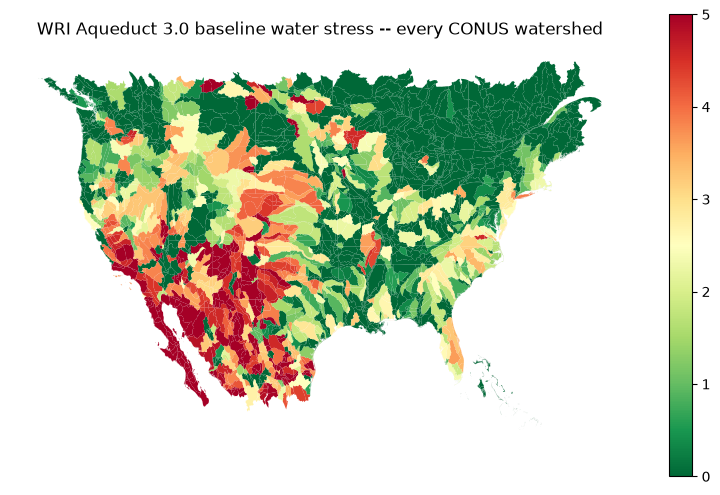

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
aqueduct.plot(column="bws_score", cmap="RdYlGn_r", legend=True, ax=ax, linewidth=0)
ax.set_title("WRI Aqueduct 3.0 baseline water stress -- every CONUS watershed")
ax.set_axis_off()
plt.show()


## 3. Clip to WA/OR and the Compact states

Each state is clipped **individually** against its own real TIGER boundary, not once against a
combined region -- a watershed that straddles WA/OR gets two clipped pieces, one per state, each
carrying only that state's real portion. Area is recomputed post-clip in an equal-area CRS
(EPSG:5070), not read off Aqueduct's pre-clip `area_km2` column, which would overstate a border
watershed's contribution to a single state's total.


In [4]:
def clip_state(aqueduct, state):
    boundary = gpd.read_file(f"{DATA}/{state}/raw/state.geojson").to_crs(aqueduct.crs)
    region = gpd.GeoDataFrame(geometry=[boundary.union_all()], crs=aqueduct.crs)
    hits = aqueduct[aqueduct.geometry.intersects(region.geometry.iloc[0])].copy()
    clipped = gpd.clip(hits, region)
    clipped = clipped[clipped.geometry.notna() & ~clipped.geometry.is_empty]
    clipped = clipped[clipped["bws_score"].notna()]
    clipped["area_km2"] = clipped.geometry.to_crs(EQUAL_AREA_CRS).area / 1e6
    clipped["state"] = state
    return clipped


pnw = gpd.GeoDataFrame(
    pd.concat([clip_state(aqueduct, s) for s in PNW_STATES], ignore_index=True), crs=aqueduct.crs
)
compact = gpd.GeoDataFrame(
    pd.concat([clip_state(aqueduct, s) for s in COMPACT_STATES], ignore_index=True), crs=aqueduct.crs
)

print(f"WA/OR:          {len(pnw):>4} watershed pieces, {pnw['area_km2'].sum():>10,.0f} km2")
print(f"Compact states: {len(compact):>4} watershed pieces, {compact['area_km2'].sum():>10,.0f} km2")


WA/OR:           322 watershed pieces,    427,305 km2
Compact states:  944 watershed pieces,  2,049,566 km2


## 4. Map -- WA/OR watershed water stress

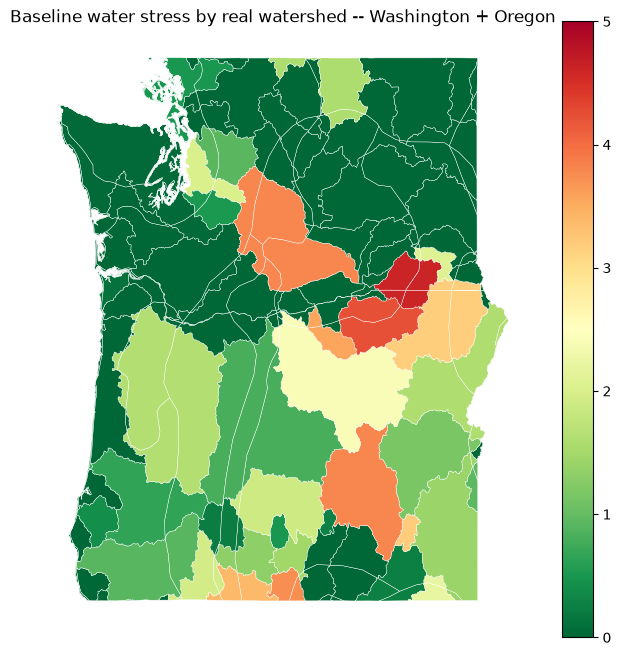

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))
pnw.plot(column="bws_score", cmap="RdYlGn_r", vmin=0, vmax=5, legend=True, ax=ax,
         edgecolor="white", linewidth=0.3)
ax.set_title("Baseline water stress by real watershed -- Washington + Oregon")
ax.set_axis_off()
plt.show()


## 5. Data-center sites -- load and join

Real tracked sites from merascope's `datacenters.db` (each backed by 2+ independent sources,
`scripts/dc_tracker.py`), not an invented list. The join to each site's watershed is a plain
`geopandas.sjoin` (`predicate="within"`) -- the geopandas-native equivalent of the manual
point-in-polygon code the production script uses (which avoids importing this notebook's
dependencies into a Flask route; a notebook has no such constraint).


In [6]:
dc_gdf = gpd.read_file(f"{SHARED}/tracked_datacenters.geojson")
dc_confirmed = dc_gdf[dc_gdf["confirmed"]].copy()
print(f"{len(dc_confirmed)} confirmed data-center sites nationally")

dc_pnw = dc_confirmed[dc_confirmed["state"].isin(PNW_STATES)].to_crs(pnw.crs)
joined_pnw = gpd.sjoin(
    dc_pnw, pnw[["aq30_id", "state", "bws_score", "area_km2", "geometry"]],
    predicate="within", how="left", lsuffix="dc", rsuffix="ws",
)
joined_pnw = joined_pnw.sort_values("bws_score", ascending=False)
joined_pnw[["name", "operator", "state_dc", "city", "bws_score"]]


36 confirmed data-center sites nationally


,name,operator,state_dc,city,bws_score
21,Amazon AWS - Hermiston (Cottonwood Bend),Amazon/AWS,OR,Hermiston,4.227360
20,Amazon AWS - McNary/Umatilla (Powerline Rd),Amazon/AWS,OR,Umatilla,4.227360
10,Westin Building Exchange,Various,WA,Seattle,2.019254
12,HorizonIQ Seattle (Tukwila),HorizonIQ,WA,Tukwila,2.019254
11,Verizon Seattle,Verizon,WA,Seattle,2.019254
9,Equinix SE2 Seattle,Equinix,WA,Seattle,2.019254
13,ColoCrossing SEA1 (Tukwila),ColoCrossing,WA,Tukwila,2.019254
32,Meta Prineville Campus,Meta,OR,Prineville,0.812558
0,Microsoft Quincy Campus,Microsoft,WA,Quincy,0.000000
3,Sabey SDC Quincy,Sabey,WA,Quincy,0.000000


## 6. Map -- data-center sites over watershed stress

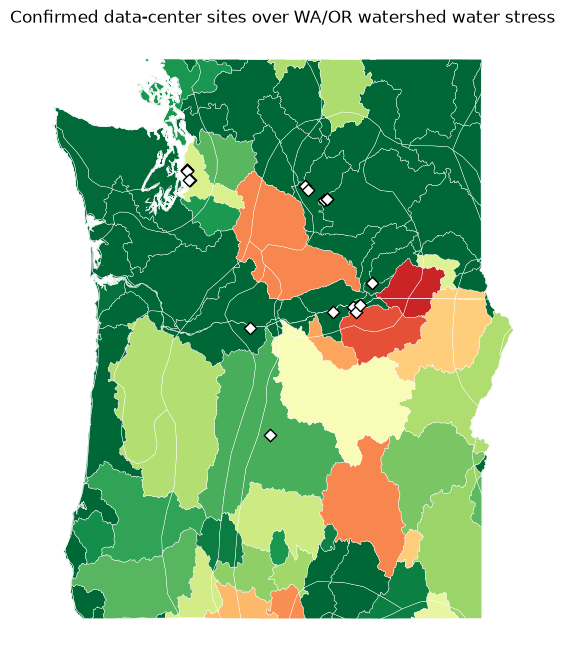

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
pnw.plot(column="bws_score", cmap="RdYlGn_r", vmin=0, vmax=5, ax=ax, edgecolor="white", linewidth=0.3)
dc_pnw.plot(ax=ax, color="white", edgecolor="black", markersize=40, marker="D", zorder=5)
ax.set_title("Confirmed data-center sites over WA/OR watershed water stress")
ax.set_axis_off()
plt.show()


## 7. Findings -- area-weighted shares

Every share below is **area-weighted** (% of km2 extremely stressed, not % of polygon count) --
polygon count would be an artifact of how Aqueduct happened to slice a given basin, not a
meaningful land measure.


In [8]:
def area_share(gdf, extreme=EXTREME):
    total = gdf["area_km2"].sum()
    extreme_area = gdf.loc[gdf["bws_score"] >= extreme, "area_km2"].sum()
    return 100.0 * extreme_area / total if total else 0.0


national_total = aqueduct.geometry.to_crs(EQUAL_AREA_CRS).area.sum() / 1e6
national_extreme = (
    aqueduct.loc[aqueduct["bws_score"] >= EXTREME].geometry.to_crs(EQUAL_AREA_CRS).area.sum() / 1e6
)
national_share = 100.0 * national_extreme / national_total

print("Area-weighted share of land at extremely high baseline water stress (bws >= 4):")
print(f"  National                     {national_share:5.1f}%")
print(f"  7 Colorado River Compact st.  {area_share(compact):5.1f}%")
print(f"  Washington + Oregon           {area_share(pnw):5.1f}%")


Area-weighted share of land at extremely high baseline water stress (bws >= 4):
  National                      15.6%
  7 Colorado River Compact st.   30.1%
  Washington + Oregon             2.6%


## 8. The extreme-stress cluster in WA/OR

In [9]:
extreme_ws = pnw[pnw["bws_score"] >= EXTREME].sort_values("bws_score", ascending=False)
print(f"{len(extreme_ws)} WA/OR watershed pieces read extremely high (bws >= {EXTREME}):\n")
for _, row in extreme_ws.iterrows():
    print(f"  watershed {row['aq30_id']}  {row['state']}  bws={row['bws_score']:.3f}  "
          f"{row['area_km2']:,.0f} km2")

floor_area = pnw.loc[pnw["bws_score"] == 0.0, "area_km2"].sum()
print(f"\n{100.0 * floor_area / pnw['area_km2'].sum():.1f}% of WA/OR land area sits at the "
      f"literal floor (bws = 0.000).")


8 WA/OR watershed pieces read extremely high (bws >= 4.0):

  watershed 58663  WA  bws=4.618  1,351 km2
  watershed 58661  WA  bws=4.618  5 km2
  watershed 58660  WA  bws=4.618  12 km2
  watershed 58662  WA  bws=4.618  1,939 km2
  watershed 58661  OR  bws=4.618  835 km2
  watershed 58660  OR  bws=4.618  418 km2
  watershed 58657  OR  bws=4.227  4,278 km2
  watershed 58656  OR  bws=4.227  2,255 km2

35.2% of WA/OR land area sits at the literal floor (bws = 0.000).


## Caveats

Not decoration -- hand these over with the finding:

- **This is local withdrawal-to-supply ratio, not Colorado River allocation risk.** Nevada and
  Utah both read low despite heavy Colorado River exposure -- Las Vegas draws ~90% of its water
  from Lake Mead while sitting in a Great Basin internal-drainage watershed that this metric
  scores separately.
- **Long-run average, not current drought conditions.**
- **Says nothing about water quality.** Boardman, OR reads the lowest possible water-stress score
  while sitting inside the Lower Umatilla Basin Groundwater Management Area, where Oregon DEQ has
  tracked nitrate contamination since 1990. A metric that clears a site on quantity says nothing
  about quality.


## Reproduce

- Numbers with assertions: `python3 scripts/analysis_pnw_water_stress.py`
- Watershed layers this notebook reads: `scripts/export_pnw_watersheds.py`
- Live page: https://datacenters.simonhansedasi.com/reports/pnw-water-stress
- Data-center tracker: `scripts/dc_tracker.py status --state WA`
